# 02 · Models and evaluation
Baselines and the main model. Splits: 70/15/15 stratified, exact duplicates removed first.
Train fits the models, validation picks hyper-parameters / early stopping / decision threshold,
**test is only used for the final numbers**.

In [1]:
import sys; sys.path.insert(0, "..")
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns, joblib
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.calibration import calibration_curve
from sklearn.metrics import roc_curve, precision_recall_curve
import lightgbm as lgb
from src.preprocess import get_splits
from src.evaluation import best_f1_threshold, threshold_for_recall, report
sns.set_theme(style="whitegrid")
X_tr, X_va, X_te, y_tr, y_va, y_te = get_splits()
for n, y in [("train", y_tr), ("val", y_va), ("test", y_te)]:
    print(f"{n:5s} n={len(y):6d}  positives={y.mean():.3f}")

train n=160631  positives=0.153
val   n= 34421  positives=0.153
test  n= 34422  positives=0.153


## 1. Baselines

In [2]:
prev = y_tr.mean()
print(f"Majority-class accuracy on test: {1-y_te.mean():.3f}  (looks good, but recall = 0)")
logreg = make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000))
logreg.fit(X_tr, y_tr)
p_lr = {k: logreg.predict_proba(X)[:,1] for k, X in [("train",X_tr),("val",X_va),("test",X_te)]}

Majority-class accuracy on test: 0.847  (looks good, but recall = 0)


## 2. Main model: LightGBM
Regularised on purpose (small leaves, `min_child_samples`, subsampling, L2) with early stopping on the
validation log-loss, so that it does not overfit.

In [3]:
gbm = lgb.LGBMClassifier(n_estimators=3000, learning_rate=0.03, num_leaves=15, min_child_samples=100,
                         subsample=0.8, subsample_freq=1, colsample_bytree=0.8, reg_lambda=5.0,
                         random_state=42, verbose=-1)
gbm.fit(X_tr, y_tr, eval_set=[(X_va, y_va)], eval_metric="binary_logloss",
        callbacks=[lgb.early_stopping(100, verbose=False)])
print("best iteration:", gbm.best_iteration_)
p_gb = {k: gbm.predict_proba(X)[:,1] for k, X in [("train",X_tr),("val",X_va),("test",X_te)]}

/usr/local/lib/python3.13/site-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


best iteration: 736


## 3. Results
The decision threshold is chosen on **validation** (maximising F1) and then applied unchanged to test.

In [4]:
ys = {"train": y_tr, "val": y_va, "test": y_te}
rows = []
for name, P in [("LogReg", p_lr), ("LightGBM", p_gb)]:
    thr = best_f1_threshold(ys["val"], P["val"])
    for split in ["train", "val", "test"]:
        rows.append({"model": name, "split": split, "thr": round(thr, 2), **report(ys[split], P[split], thr)})
res = pd.DataFrame(rows).round(3)
res

,model,split,thr,ROC-AUC,PR-AUC,Brier,F1,Precision,Recall
0,LogReg,train,0.22,0.806,0.405,0.108,0.461,0.371,0.608
1,LogReg,val,0.22,0.812,0.421,0.107,0.466,0.373,0.620
2,LogReg,test,0.22,0.807,0.404,0.108,0.461,0.369,0.613
3,LightGBM,train,0.24,0.825,0.460,0.104,0.485,0.396,0.627
4,LightGBM,val,0.24,0.821,0.449,0.105,0.477,0.387,0.622
5,LightGBM,test,0.24,0.818,0.442,0.105,0.474,0.385,0.615


In [5]:
res[res.split=="test"].set_index("model").drop(columns="split")

,thr,ROC-AUC,PR-AUC,Brier,F1,Precision,Recall
model,,,,,,,
LogReg,0.22,0.807,0.404,0.108,0.461,0.369,0.613
LightGBM,0.24,0.818,0.442,0.105,0.474,0.385,0.615


### Overfitting check
Train vs validation vs test gap for the main metrics (a large train–test gap would signal overfitting).

In [6]:
piv = res[res.model=="LightGBM"].set_index("split")[["ROC-AUC","PR-AUC","F1","Brier"]]
piv

,ROC-AUC,PR-AUC,F1,Brier
split,,,,
train,0.825,0.460,0.485,0.104
val,0.821,0.449,0.477,0.105
test,0.818,0.442,0.474,0.105


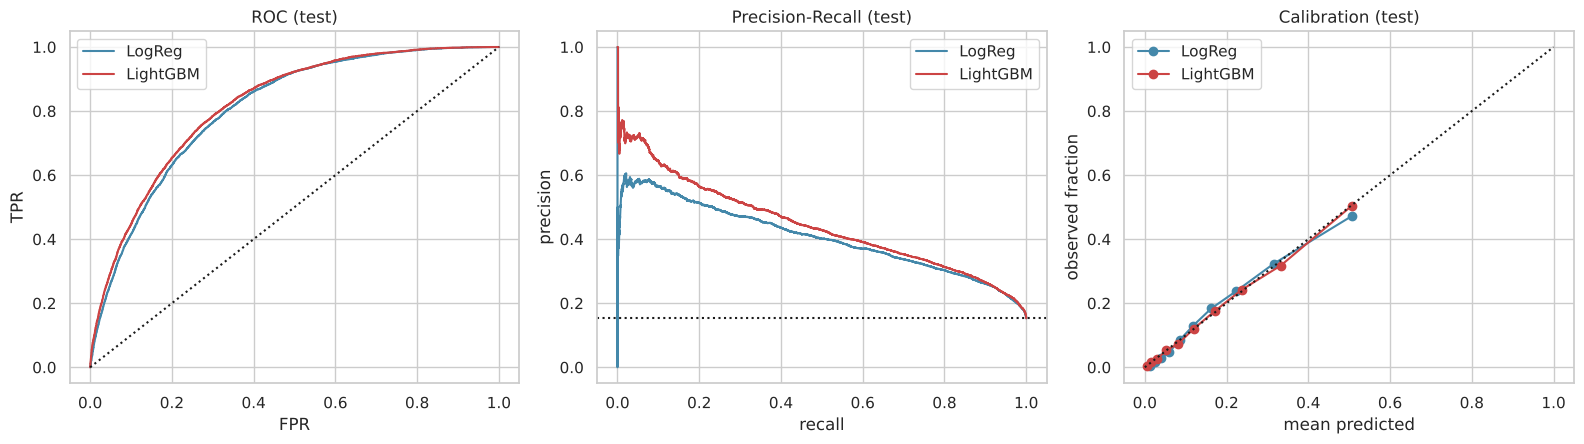

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.6))
for name, P, c in [("LogReg", p_lr, "#48a"), ("LightGBM", p_gb, "#c44")]:
    fpr, tpr, _ = roc_curve(y_te, P["test"]); axes[0].plot(fpr, tpr, c=c, label=name)
    pr, rc, _ = precision_recall_curve(y_te, P["test"]); axes[1].plot(rc, pr, c=c, label=name)
    fr, mp = calibration_curve(y_te, P["test"], n_bins=10, strategy="quantile"); axes[2].plot(mp, fr, "o-", c=c, label=name)
axes[0].plot([0,1],[0,1],"k:"); axes[0].set(title="ROC (test)", xlabel="FPR", ylabel="TPR")
axes[1].axhline(y_te.mean(), c="k", ls=":"); axes[1].set(title="Precision-Recall (test)", xlabel="recall", ylabel="precision")
axes[2].plot([0,1],[0,1],"k:"); axes[2].set(title="Calibration (test)", xlabel="mean predicted", ylabel="observed fraction")
for a in axes: a.legend()
plt.tight_layout(); plt.savefig("../figures/models_curves.png", dpi=150); plt.show()

## 4. Operating point: screening threshold
For a screening programme, missing a diabetic person costs more than an extra confirmatory test.
We therefore set the final operating point to **recall >= 80 % on validation** (threshold chosen on validation, applied to test),
instead of the F1-optimal threshold used above for comparing models.

In [8]:
thr80 = threshold_for_recall(y_va, p_gb["val"], 0.80)
rows = []
for split in ["val", "test"]:
    r = report(ys[split], p_gb[split], thr80)
    rows.append({"split": split, "thr": round(thr80, 3), "flagged": (p_gb[split] >= thr80).mean(), **r})
pd.DataFrame(rows).round(3)

,split,thr,flagged,ROC-AUC,PR-AUC,Brier,F1,Precision,Recall
0,val,0.148,0.387,0.821,0.449,0.105,0.455,0.317,0.802
1,test,0.148,0.390,0.818,0.442,0.105,0.450,0.313,0.799


In [9]:
import os; os.makedirs("../models", exist_ok=True)
joblib.dump(gbm, "../models/lightgbm.joblib"); joblib.dump(logreg, "../models/logreg.joblib")
print("saved models")

saved models
